# Simple model: viewer rating
Predict TMDB `vote_average` with ordinary linear regression. Report MAE, RMSE, and R² against predicting the training mean rating.

Use **9 predictors instead of 39**, read from the existing feature-engineering output. The original baseline is fixed. Optional Section 5 compares six compact feature presets without changing estimator settings or the success threshold. Run from this folder with `ds6001`; no CSVs or model files are written.

## Tuning controls — edit here first

1. Edit the controls in the next cell.
2. **Save the notebook and Run All** so every result uses the same settings.
3. Review the validation table, then the later-test table. Do not repeatedly tune against test scores.

| What you want to change | Control |
|---|---|
| Original model or a setting not searched | `MODEL_SETTINGS` |
| Baseline inputs and small feature presets | `NUMERIC_FEATURES`, `BINARY_FEATURES`, and `FEATURE_SETS` |
| Date boundary and number of validation folds | `CUTOFF_DATE`, `N_VALIDATION_SPLITS`; keep consistent across models |

This simple model does not search hyperparameters. Changing `MODEL_SETTINGS` changes the fixed estimator in every preset; selection compares the configured feature presets by MAE.

**Example:** Edit a list in `FEATURE_SETS` to add/remove an input, keeping presets at most 10 predictors. Keep the original reference preset. Keep parameter key names unchanged when editing trial values.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_rating.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {}

# CHANGE THE FEATURE LISTS below to try small models (up to 10 inputs per preset).
NUMERIC_FEATURES = ["runtime", "dir_prior_films_log1p", "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p"]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = ["is_sequel", "is_english", "dir_no_rating_history"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES

basics = ["runtime", "us_certification", "release_month", "is_sequel", "is_english"]
FEATURE_SETS = {
    "Movie basics": basics,
    "+ Director experience": basics + ["dir_prior_films_log1p"],
    "Original director history": FEATURE_COLUMNS,
    "Actor/company/franchise": basics + [
        "lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable",
        "company_films_5yr_log1p", "franchise_prior_films_log1p",
    ],
    "Basics + four genres": basics + ["genre_drama", "genre_comedy", "genre_action", "genre_horror"],
    "Compact mix": basics + [
        "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
        "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    ],
}

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert "Original director history" in FEATURE_SETS  # Keep the original reference preset.


## 1. Load data and choose nine predictors
Use runtime, director experience, smoothed mean rating of observed earlier director films and the number of rated earlier titles, certification, release month, sequel status, English-language status, and a director-history availability flag.

Four numeric predictors, two categorical predictors, and three binary indicators keep the model small. Counts are already `log1p` transformed in the source table. Both current-movie targets and identifiers are excluded from predictors.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
TARGET = "vote_average"

assert FEATURE_COLUMNS and len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(FEATURE_COLUMNS)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()
X = movies[FEATURE_COLUMNS].copy()
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies[TARGET].copy()
assert y.notna().all()
print(f"{len(movies):,} movies | {len(FEATURE_COLUMNS)} predictors | Target: {TARGET}")
display(pd.DataFrame({
    "Predictor": FEATURE_COLUMNS,
    "Role": ["Numeric"] * len(NUMERIC_FEATURES) + ["Categorical"] * len(CATEGORICAL_FEATURES) + ["Binary"] * len(BINARY_FEATURES),
}))
assert y.between(0, 10).all()

13,276 movies | 9 predictors | Target: vote_average


,Predictor,Role
0,runtime,Numeric
1,dir_prior_films_log1p,Numeric
2,dir_prior_rating_smoothed,Numeric
3,dir_prior_rated_films_log1p,Numeric
4,us_certification,Categorical
5,release_month,Categorical
6,is_sequel,Binary
7,is_english,Binary
8,dir_no_rating_history,Binary


## 2. Split by release date
Read `model_data_rating.csv`, built from the broader combined data without budget/revenue filters. Retain the previous experiment's fixed date cutoff **2017-11-18**: train before it and test on or after it. All movies sharing a date stay together. The expanded cohort has 9,405 training and 3,871 test movies (about 71/29, rather than the previous 80/20).

Training-only chronological folds are rebuilt within this expanded training set. Broader test-population scores are not directly comparable with earlier scores on only financially eligible movies. These data have already been inspected, so results remain exploratory.

In [3]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train = movies["release_date"].lt(cutoff)
test = ~train
X_train, X_test = X.loc[train], X.loc[test]
y_train, y_test = y.loc[train], y.loc[test]
assert movies.loc[train, "release_date"].max() < movies.loc[test, "release_date"].min()
assert set(movies.loc[train, "tmdb_id"]).isdisjoint(movies.loc[test, "tmdb_id"])
display(pd.DataFrame([
    ["Training", len(y_train), movies.loc[train, "release_date"].min(), movies.loc[train, "release_date"].max()],
    ["Test", len(y_test), movies.loc[test, "release_date"].min(), movies.loc[test, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,9405,1990-01-12,2017-11-17
1,Test,3871,2017-11-18,2025-12-28


## 3. Fit Linear regression
Build the original reference model with **`MODEL_SETTINGS` in the top Tuning controls cell**. Change searched values in `PARAM_GRID` where available; values in that grid override the original settings during search. The simple notebooks keep the estimator fixed across feature presets.

Imputation, scaling, and categorical encoding are fitted on training data only. Binary flags pass through unchanged. No current-movie outcome is a predictor.

In [4]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL_FEATURES),
    ("binary", "passthrough", BINARY_FEATURES),
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression(**MODEL_SETTINGS)),
])
model.fit(X_train, y_train)
train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)
baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))

## 4. Evaluate
Compare the training and later-test results with a simple baseline, then inspect the first ten test predictions.

,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6123,0.7746,-0.0734
1,Simple linear regression,Training,0.5544,0.7093,0.2177
2,Simple linear regression,Test,0.5512,0.7036,0.1143


,title_tmdb,vote_average,predicted_rating
9405,Revenge,6.500,6.841
9406,Darkest Hour,7.400,6.673
9407,Le Brio,7.000,6.349
9408,In the Fade,6.898,6.810
9409,Forgotten,7.900,6.634
9410,I Can Quit Whenever I Want 3: Ad Honorem,7.300,6.384
9411,The Shape of Water,7.200,6.558
9412,"Three Billboards Outside Ebbing, Missouri",8.051,6.507
9413,Wonder Wheel,6.400,6.202
9414,Perfect Strangers,6.684,6.699


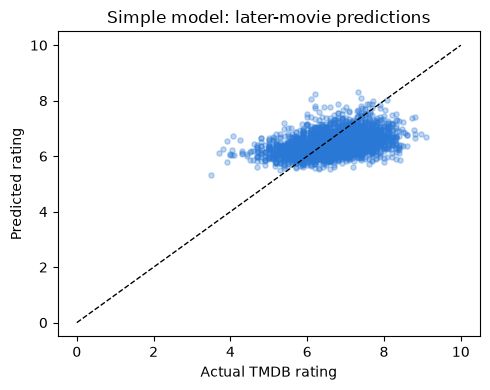

In [5]:
def score(name, split, actual, predicted):
    return {
        "Model": name, "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }
results = pd.DataFrame([
    score("Training mean baseline", "Test", y_test, baseline_prediction),
    score("Simple linear regression", "Training", y_train, train_prediction),
    score("Simple linear regression", "Test", y_test, test_prediction),
])
display(results.round(4))
examples = movies.loc[test, ["title_tmdb", "vote_average"]].copy()
examples["predicted_rating"] = test_prediction
display(examples.head(10).round(3))
plt.figure(figsize=(5, 4))
plt.scatter(y_test, test_prediction, alpha=0.3, s=14, color="#2a78d6")
plt.plot([0, 10], [0, 10], "k--", linewidth=1)
plt.xlabel("Actual TMDB rating")
plt.ylabel("Predicted rating")
plt.title("Simple model: later-movie predictions")
plt.tight_layout()
plt.show()

## 5. Compare small feature sets
Try six named presets, each with **5–10 predictors**. Keep the same estimator settings and success threshold (0.5); only predictors change. Three expanding chronological validation folds stay entirely inside the original training period, with fresh preprocessing fitted in every fold.

Select the preset with the lowest **mean validation MAE**.

Refit the validation-selected preset on all training movies and compare it with the original nine-feature model on the same later test rows. Do not choose a preset from its test score. This is exploratory comparison on already-inspected data, not independent confirmation of improvement. You can edit `feature_versions` to define another small preset before rerunning.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [6]:
from sklearn.model_selection import TimeSeriesSplit

feature_versions = FEATURE_SETS
assert all(len(columns) <= 10 and len(columns) == len(set(columns)) for columns in feature_versions.values())
comparison_features = list(dict.fromkeys(column for columns in feature_versions.values() for column in columns))
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(comparison_features)
comparison_X = movies[comparison_features].copy()
for column in CATEGORICAL_FEATURES:
    comparison_X[column] = comparison_X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
comparison_binary = BINARY_FEATURES + ["backfill_unavailable"] + [column for column in movies if column.startswith("genre_")]

# Same model and preprocessing rules for every preset.
def make_feature_model(columns):
    numeric = [column for column in columns if column not in CATEGORICAL_FEATURES + comparison_binary]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in columns if column in comparison_binary]
    return Pipeline([
        ("preprocessor", ColumnTransformer([
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
            ]), categorical),
            ("binary", "passthrough", binary),
        ])),
        ("model", LinearRegression(**MODEL_SETTINGS)),
    ])

training_dates = movies.loc[train, "release_date"]
unique_dates = np.sort(training_dates.unique())
feature_splits = []
for earlier, later in TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates):
    fit_rows = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_rows = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_rows, "release_date"].max() < movies.loc[validation_rows, "release_date"].min()
    assert set(fit_rows).union(validation_rows).issubset(set(y_train.index))
    feature_splits.append((fit_rows, validation_rows))

fold_results = []
for version, columns in feature_versions.items():
    for fold, (fit_rows, validation_rows) in enumerate(feature_splits, 1):
        candidate = make_feature_model(columns)
        candidate.fit(comparison_X.loc[fit_rows], y.loc[fit_rows])
        predicted = candidate.predict(comparison_X.loc[validation_rows])
        metrics = score(version, "Validation", y.loc[validation_rows], predicted)
        fold_results.append({"Version": version, "Fold": fold, "Predictors": len(columns), **{key: metrics[key] for key in ["MAE", "RMSE", "R2"]}})
feature_fold_results = pd.DataFrame(fold_results)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"), MAE=("MAE", "mean"),
    MAE_std=("MAE", "std"), RMSE=("RMSE", "mean"), R2=("R2", "mean"),
)
selected_version = feature_comparison["MAE"].idxmin()
with pd.option_context("display.max_columns", None):
    display(feature_comparison.round(4))
print("Selected using training-period validation:", selected_version)
selected_columns = feature_versions[selected_version]
print("Selected predictors:", selected_columns)

feature_selected_model = make_feature_model(selected_columns)
feature_selected_model.fit(comparison_X.loc[train], y_train)
selected_prediction = feature_selected_model.predict(comparison_X.loc[test])
selected_test_result = score("Validation-selected simple model", "Test", y_test, selected_prediction)
comparison_test_results = pd.concat([results.loc[results["Split"].eq("Test")], pd.DataFrame([selected_test_result])], ignore_index=True)
display(comparison_test_results.round(4))
print("The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.")
assert len(feature_fold_results) == len(feature_versions) * N_VALIDATION_SPLITS

,Predictors,MAE,MAE_std,RMSE,R2
Version,,,,,
Movie basics,5,0.5712,0.0109,0.7364,0.1646
+ Director experience,6,0.5712,0.0126,0.7366,0.1641
Original director history,9,0.5647,0.0180,0.7270,0.1857
Actor/company/franchise,9,0.5702,0.0129,0.7373,0.1626
Basics + four genres,9,0.5431,0.0073,0.7009,0.2431
Compact mix,10,0.5607,0.0180,0.7215,0.1980


Selected using training-period validation: Basics + four genres
Selected predictors: ['runtime', 'us_certification', 'release_month', 'is_sequel', 'is_english', 'genre_drama', 'genre_comedy', 'genre_action', 'genre_horror']


,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6123,0.7746,-0.0734
1,Simple linear regression,Test,0.5512,0.7036,0.1143
2,Validation-selected simple model,Test,0.5619,0.7144,0.0869


The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.


## Interpretation
Lower MAE/RMSE is better; MAE is measured in rating points. Higher R² is better. Compare with the mean-rating baseline first. Predictions are not clipped to 0–10. A simpler model is easier to explain but may not predict as well as the larger models.

History covers observed earlier films and uses retrospective snapshots, not a complete director filmography or verified historical ratings/outcomes. Earlier-year histories update through time, representing rolling predictions. Results describe the broader matched rating cohort and the already-inspected later period, so they are exploratory. Keep the same evaluation rows when comparing simple and detailed models.

## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [7]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("simple_model.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/rating/simple_model.json
